## 1. Introducción

En este proyecto realizo un análisis exploratorio de datos (EDA) sobre una campaña 
de marketing telefónico de un banco portugués. El objetivo es entender qué factores 
influyen en que un cliente contrate un depósito a plazo.

**Datasets utilizados:**
- `bank-additional.csv`: datos de 43.000 llamadas de la campaña
- `customer-details.xlsx`: información de los clientes (3 años: 2012, 2013, 2014)

In [186]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8')
sns.set_palette("husl")

print("Librerías cargadas correctamente ✓")

Librerías cargadas correctamente ✓


In [187]:
# Cargamos el dataset principal de la campaña de marketing

bank = pd.read_csv(r'C:\Users\mmontllo\Desktop\DATA ANALYTICS\Python for data\proyecto-eda\data\raw\bank-additional.csv', sep=',')

print("Shape:", bank.shape)
print("\nColumnas:", bank.columns.tolist())

Shape: (43000, 24)

Columnas: ['Unnamed: 0', 'age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y', 'date', 'latitude', 'longitude', 'id_']


In [188]:
# Cargamos el Excel con las 3 hojas
xl = pd.ExcelFile(r'C:\Users\mmontllo\Desktop\DATA ANALYTICS\Python for data\proyecto-eda\data\raw\customer-details.xlsx')

print("Hojas disponibles:", xl.sheet_names)

# Cargamos cada hoja
demographics = pd.read_excel(xl, sheet_name=xl.sheet_names[0])
financials = pd.read_excel(xl, sheet_name=xl.sheet_names[1])
segments = pd.read_excel(xl, sheet_name=xl.sheet_names[2])

print("\ndemographics shape:", demographics.shape)
print("financials shape:", financials.shape)
print("segments shape:", segments.shape)

Hojas disponibles: ['2012', '2013', '2014']

demographics shape: (20115, 7)
financials shape: (8965, 7)
segments shape: (14090, 7)


In [189]:
print("=== 2012 ===")
print(demographics.columns.tolist())
print(demographics.head(3))

print("\n=== 2013 ===")
print(financials.columns.tolist())
print(financials.head(3))

print("\n=== 2014 ===")
print(segments.columns.tolist())
print(segments.head(3))

=== 2012 ===
['Unnamed: 0', 'Income', 'Kidhome', 'Teenhome', 'Dt_Customer', 'NumWebVisitsMonth', 'ID']
   Unnamed: 0  Income  Kidhome  Teenhome Dt_Customer  NumWebVisitsMonth  \
0           0  161770        1         0  2012-04-04                 29   
1           1   85477        1         1  2012-12-30                  7   
2           2  147233        1         1  2012-02-02                  5   

                                     ID  
0  089b39d8-e4d0-461b-87d4-814d71e0e079  
1  e9d37224-cb6f-4942-98d7-46672963d097  
2  3f9f49b5-e410-4948-bf6e-f9244f04918b  

=== 2013 ===
['Unnamed: 0', 'Income', 'Kidhome', 'Teenhome', 'Dt_Customer', 'NumWebVisitsMonth', 'ID']
   Unnamed: 0  Income  Kidhome  Teenhome Dt_Customer  NumWebVisitsMonth  \
0           0   82407        0         1  2013-10-07                 29   
1           1   24877        0         0  2013-04-21                 32   
2           2   78839        1         0  2013-11-25                 21   

                       

In [190]:
# Las 3 hojas tienen la misma estructura, las unimos con concat
# Añadimos columna 'year' para saber de qué año viene cada registro
demographics['year'] = 2012
financials['year'] = 2013
segments['year'] = 2014

customers = pd.concat([demographics, financials, segments], ignore_index=True)

print("Shape total customers:", customers.shape)
print("\nDistribución por año:")
print(customers['year'].value_counts().sort_index())

Shape total customers: (43170, 8)

Distribución por año:
year
2012    20115
2013     8965
2014    14090
Name: count, dtype: int64


In [191]:
# Unimos bank con customers usando el ID del cliente
# bank tiene 'id_' y customers tiene 'ID'
df = bank.merge(customers, left_on='id_', right_on='ID', how='left')

print("Shape después del merge:", df.shape)
print("\nValores nulos por columna:")
print(df.isnull().sum())

Shape después del merge: (43000, 32)

Valores nulos por columna:
Unnamed: 0_x            0
age                  5120
job                   345
marital                85
education            1807
default              8981
housing              1026
loan                 1026
contact                 0
duration                0
campaign                0
pdays                   0
previous                0
poutcome                0
emp.var.rate            0
cons.price.idx        471
cons.conf.idx           0
euribor3m            9256
nr.employed             0
y                       0
date                  248
latitude                0
longitude               0
id_                     0
Unnamed: 0_y            0
Income                  0
Kidhome                 0
Teenhome                0
Dt_Customer             0
NumWebVisitsMonth       0
ID                      0
year                    0
dtype: int64


In [192]:
# Resumen estadístico del dataset combinado
print("=== INFORMACIÓN GENERAL ===")
print(df.info())

=== INFORMACIÓN GENERAL ===
<class 'pandas.DataFrame'>
RangeIndex: 43000 entries, 0 to 42999
Data columns (total 32 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Unnamed: 0_x       43000 non-null  int64         
 1   age                37880 non-null  float64       
 2   job                42655 non-null  str           
 3   marital            42915 non-null  str           
 4   education          41193 non-null  str           
 5   default            34019 non-null  float64       
 6   housing            41974 non-null  float64       
 7   loan               41974 non-null  float64       
 8   contact            43000 non-null  str           
 9   duration           43000 non-null  int64         
 10  campaign           43000 non-null  int64         
 11  pdays              43000 non-null  int64         
 12  previous           43000 non-null  int64         
 13  poutcome           43000 non-null  str      

In [193]:
# Estadísticas descriptivas de las columnas numéricas
df.describe()

,Unnamed: 0_x,age,default,housing,loan,duration,campaign,pdays,previous,emp.var.rate,latitude,longitude,Unnamed: 0_y,Income,Kidhome,Teenhome,Dt_Customer,NumWebVisitsMonth,year
count,43000.000000,37880.000000,34019.000000,41974.000000,41974.000000,43000.000000,43000.000000,43000.000000,43000.000000,43000.000000,43000.000000,43000.000000,43000.000000,43000.000000,43000.000000,43000.000000,43000,43000.000000,43000.000000
mean,20651.099047,39.977112,0.000088,0.535998,0.155620,257.739279,2.567233,962.330953,0.174023,0.077128,36.856697,-95.939067,7935.478930,93241.200070,1.004791,0.998605,2013-05-12 07:05:06.083721,16.589698,2012.861535
min,0.000000,17.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,-3.400000,24.396000,-124.997000,0.000000,5841.000000,0.000000,0.000000,2012-01-01 00:00:00,1.000000,2012.000000
25%,10381.750000,32.000000,0.000000,0.000000,0.000000,102.000000,1.000000,999.000000,0.000000,-1.800000,30.614750,-110.494250,3615.000000,49610.000000,0.000000,0.000000,2012-07-16 00:00:00,9.000000,2012.000000
50%,20642.500000,38.000000,0.000000,1.000000,0.000000,179.000000,2.000000,999.000000,0.000000,1.100000,36.761000,-95.899500,7222.000000,93050.500000,1.000000,1.000000,2013-03-02 00:00:00,17.000000,2013.000000
75%,30930.250000,47.000000,0.000000,1.000000,0.000000,319.000000,3.000000,999.000000,0.000000,1.400000,43.113250,-81.427750,11725.250000,136744.500000,2.000000,2.000000,2014-03-29 00:00:00,25.000000,2014.000000
max,41187.000000,98.000000,1.000000,1.000000,1.000000,4918.000000,56.000000,999.000000,7.000000,1.400000,49.384000,-66.937000,20114.000000,180802.000000,2.000000,2.000000,2014-12-31 00:00:00,32.000000,2014.000000
std,11868.770913,10.437957,0.009390,0.498708,0.362499,258.666033,2.772294,187.260394,0.497366,1.573898,7.225948,16.752282,5225.658105,50498.316182,0.815913,0.815983,NaN,9.239205,0.879460


## 2. Exploración inicial

Cargamos los dos datasets y los unimos mediante un LEFT JOIN usando el ID del cliente.

- **bank-additional.csv**: 43.000 registros de campañas de marketing bancario
- **customer-details.xlsx**: datos de clientes de 2012, 2013 y 2014 (43.170 registros en total)
- **Dataset combinado**: 43.000 filas × 32 columnas

Observaciones iniciales:
- Hay valores nulos en varias columnas (euribor3m, default, age...)
- Las columnas numéricas tienen rangos muy distintos
- La variable objetivo es `y` (si el cliente contrató el depósito: yes/no)

In [194]:
# Eliminamos columnas que no necesitamos (índices duplicados)
df = df.drop(columns=['Unnamed: 0_x', 'Unnamed: 0_y', 'ID'])

In [195]:
# Renombramos id_ para que sea más claro
df = df.rename(columns={'id_': 'customer_id'})

print("Columnas finales:", df.columns.tolist())
print("Shape:", df.shape)

Columnas finales: ['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y', 'date', 'latitude', 'longitude', 'customer_id', 'Income', 'Kidhome', 'Teenhome', 'Dt_Customer', 'NumWebVisitsMonth', 'year']
Shape: (43000, 29)


In [196]:
# Analizamos los valores nulos
nulos = df.isnull().sum()
nulos_pct = (nulos / len(df) * 100).round(2)

nulos_df = pd.DataFrame({'nulos': nulos, 'porcentaje': nulos_pct})
nulos_df = nulos_df[nulos_df['nulos'] > 0].sort_values('porcentaje', ascending=False)

print("Columnas con valores nulos:")
print(nulos_df)

Columnas con valores nulos:
                nulos  porcentaje
euribor3m        9256       21.53
default          8981       20.89
age              5120       11.91
education        1807        4.20
loan             1026        2.39
housing          1026        2.39
cons.price.idx    471        1.10
job               345        0.80
date              248        0.58
marital            85        0.20


In [197]:
# Convertimos columnas numéricas que se leyeron como texto
df['euribor3m'] = pd.to_numeric(df['euribor3m'], errors='coerce')
df['cons.price.idx'] = pd.to_numeric(df['cons.price.idx'], errors='coerce')
df['age'] = pd.to_numeric(df['age'], errors='coerce')

# Ahora sí rellenamos los nulos
df['euribor3m'] = df['euribor3m'].fillna(df['euribor3m'].median())
df['cons.price.idx'] = df['cons.price.idx'].fillna(df['cons.price.idx'].median())
df['age'] = df['age'].fillna(df['age'].median())
df['default'] = df['default'].fillna(0)
df['education'] = df['education'].fillna('unknown')
df['job'] = df['job'].fillna('unknown')
df['marital'] = df['marital'].fillna('unknown')
df['housing'] = df['housing'].fillna(df['housing'].mode()[0])
df['loan'] = df['loan'].fillna(df['loan'].mode()[0])
df = df.dropna(subset=['date'])

print("Nulos restantes:", df.isnull().sum().sum())
print("Shape final:", df.shape)

Nulos restantes: 42752
Shape final: (42752, 29)


In [198]:
print(df.isnull().sum()[df.isnull().sum() > 0])

cons.price.idx    42752
dtype: int64


In [199]:
# cons.price.idx está completamente vacía tras el merge, la eliminamos
df = df.drop(columns=['cons.price.idx'])

print("Nulos restantes:", df.isnull().sum().sum())
print("Shape final:", df.shape)

Nulos restantes: 0
Shape final: (42752, 28)


## 3. Limpieza de datos

Se han tratado los valores nulos de la siguiente manera:
- Variables numéricas (age, euribor3m): imputación con la mediana
- Variables categóricas (job, education, marital): imputación con 'unknown'
- Variables binarias (default, housing, loan): imputación con la moda
- cons.price.idx: eliminada (sin datos tras el merge)
- date: eliminadas 248 filas con valor nulo (0.58% del total)

Dataset final: **42.752 filas × 28 columnas**, sin valores nulos.

In [200]:
# ¿Cuántos clientes contrataron el depósito?
print("Distribución variable objetivo 'y':")
print(df['y'].value_counts())
print("\nEn porcentaje:")
print(df['y'].value_counts(normalize=True).round(3) * 100)

Distribución variable objetivo 'y':
y
no     37941
yes     4811
Name: count, dtype: int64

En porcentaje:
y
no     88.7
yes    11.3
Name: proportion, dtype: float64


## 4. Análisis descriptivo y visualizaciones

### Nuevas variables y segmentación por edad

Creamos una variable nueva categorizando la edad en franjas para facilitar el análisis 
por segmentos de población.

In [201]:
# Creamos una columna nueva: franjas de edad
def franja_edad(edad):
    if edad < 30:
        return 'joven'
    elif edad < 45:
        return 'adulto'
    elif edad < 60:
        return 'maduro'
    else:
        return 'senior'

df['franja_edad'] = df['age'].apply(franja_edad)

# List comprehension: lista de clientes con más de 3 contactos en la campaña
clientes_muchos_contactos = [i for i in df['campaign'] if i > 3]
print(f"Clientes contactados más de 3 veces: {len(clientes_muchos_contactos)}")

# Tasa de conversión por franja de edad
conversion_edad = df.groupby('franja_edad')['y'].apply(lambda x: (x == 'yes').sum() / len(x) * 100).round(2)
print("\nConversión por franja de edad (%):")
print(conversion_edad)

Clientes contactados más de 3 veces: 7916

Conversión por franja de edad (%):
franja_edad
adulto     9.91
joven     16.14
maduro     9.22
senior    39.47
Name: y, dtype: float64


### Filtrado con loc: clientes senior que contrataron

In [202]:
# Filtramos clientes seniors que contrataron el depósito con loc
seniors_yes = df.loc[(df['franja_edad'] == 'senior') & (df['y'] == 'yes')]
print(f"Clientes senior que contrataron: {len(seniors_yes)}")
print(f"Media de ingresos de este grupo: {seniors_yes['Income'].mean():.0f}")

Clientes senior que contrataron: 431
Media de ingresos de este grupo: 95176


In [203]:
# Correlación entre variables numéricas (sin euribor3m que tiene problemas de tipo)
columnas_numericas = ['age', 'duration', 'campaign', 'previous', 'Income', 'NumWebVisitsMonth']

correlaciones = df[columnas_numericas].corr().round(2)
print("Matriz de correlaciones:")
print(correlaciones)

Matriz de correlaciones:
                    age  duration  campaign  previous  Income  \
age                1.00      0.00      0.01      0.02     0.0   
duration           0.00      1.00     -0.07      0.02    -0.0   
campaign           0.01     -0.07      1.00     -0.08    -0.0   
previous           0.02      0.02     -0.08      1.00    -0.0   
Income             0.00     -0.00     -0.00     -0.00     1.0   
NumWebVisitsMonth -0.00      0.00      0.00     -0.00     0.0   

                   NumWebVisitsMonth  
age                             -0.0  
duration                         0.0  
campaign                         0.0  
previous                        -0.0  
Income                           0.0  
NumWebVisitsMonth                1.0  


### Observación sobre correlaciones

La matriz de correlaciones muestra que las variables numéricas del dataset 
apenas tienen relación entre sí. Esto indica que cada variable aporta 
información independiente y no hay redundancia entre ellas.

### Observación clave

Solo el **12.1% de los clientes** contactados contrató el depósito a plazo (`yes`), 
frente al 87.9% que no lo hizo. Esto indica un dataset **desbalanceado**.

In [204]:
# Tasa de conversión por tipo de trabajo
conversion_job = df.groupby('job')['y'].apply(lambda x: (x == 'yes').sum() / len(x) * 100).round(2)
conversion_job = conversion_job.sort_values(ascending=False)

print("Tasa de conversión por trabajo (%):")
print(conversion_job)

Tasa de conversión por trabajo (%):
job
student          31.36
retired          25.25
unemployed       14.45
admin.           12.98
unknown          11.34
management       11.13
self-employed    10.86
technician       10.84
housemaid         9.94
entrepreneur      8.22
services          8.05
blue-collar       6.89
Name: y, dtype: float64


### Conversión por tipo de trabajo

Los **estudiantes (31.4%)** y **jubilados (25.2%)** tienen tasas de conversión muy superiores 
a la media (12.1%). Los trabajadores de cuello azul (`blue-collar`) son los que menos convierten (6.9%).

In [205]:
# Tasa de conversión por nivel educativo
conversion_edu = df.groupby('education')['y'].apply(lambda x: (x == 'yes').sum() / len(x) * 100).round(2)
conversion_edu = conversion_edu.sort_values(ascending=False)

print("Tasa de conversión por educación (%):")
print(conversion_edu)

Tasa de conversión por educación (%):
education
illiterate             22.22
unknown                14.44
university.degree      13.68
professional.course    11.38
high.school            10.84
basic.4y               10.34
basic.6y                8.17
basic.9y                7.77
Name: y, dtype: float64


In [206]:
# Analizamos la edad media de los que contratan vs no contratan
edad_conversion = df.groupby('y')['age'].agg(['mean', 'median', 'std']).round(2)
print("Edad por resultado de campaña:")
print(edad_conversion)

Edad por resultado de campaña:
      mean  median    std
y                        
no   39.64    38.0   9.33
yes  40.56    38.0  13.03


## 5. Visualizaciones

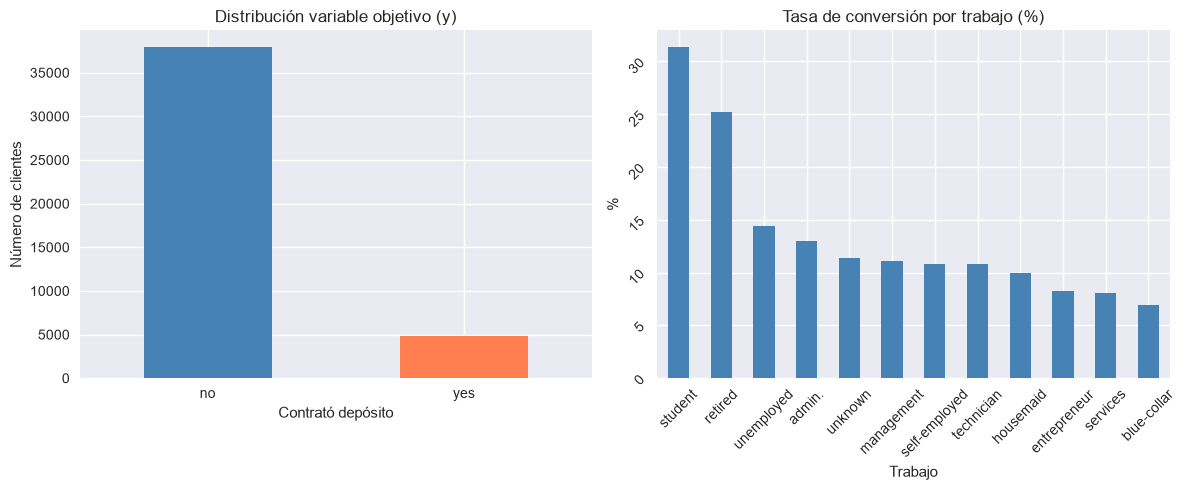

In [207]:
# Distribución de la variable objetivo y conversión por trabajo

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Gráfico 1: distribución de la variable objetivo
df['y'].value_counts().plot(kind='bar', ax=axes[0], color=['steelblue', 'coral'])
axes[0].set_title('Distribución variable objetivo (y)')
axes[0].set_xlabel('Contrató depósito')
axes[0].set_ylabel('Número de clientes')
axes[0].tick_params(rotation=0)

# Gráfico 2: tasa de conversión por trabajo
conversion_job.plot(kind='bar', ax=axes[1], color='steelblue')
axes[1].set_title('Tasa de conversión por trabajo (%)')
axes[1].set_xlabel('Trabajo')
axes[1].set_ylabel('%')
axes[1].tick_params(rotation=45)

plt.tight_layout()
plt.savefig('../data/processed/plot_conversion.png', dpi=100)
plt.show()

### Distribución de edad y nivel educativo

Analizamos cómo se distribuye la edad entre los clientes que contratan y los que no, 
y si el nivel educativo influye en la conversión.

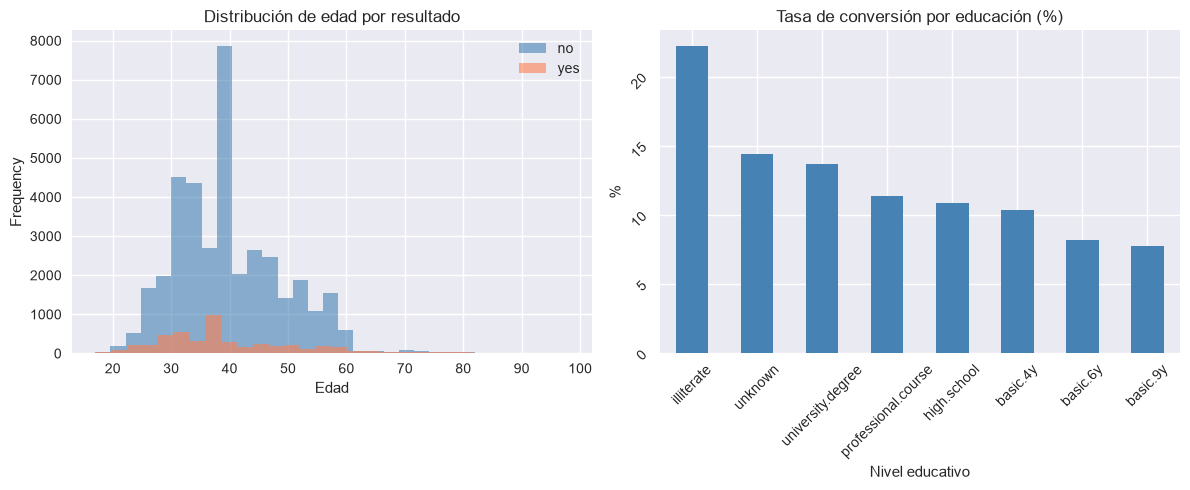

In [208]:
# Gráfico: distribución de edad por resultado
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Histograma de edad
df[df['y'] == 'no']['age'].plot(kind='hist', ax=axes[0], alpha=0.6, label='no', bins=30, color='steelblue')
df[df['y'] == 'yes']['age'].plot(kind='hist', ax=axes[0], alpha=0.6, label='yes', bins=30, color='coral')
axes[0].set_title('Distribución de edad por resultado')
axes[0].set_xlabel('Edad')
axes[0].legend()

# Tasa de conversión por educación
conversion_edu.plot(kind='bar', ax=axes[1], color='steelblue')
axes[1].set_title('Tasa de conversión por educación (%)')
axes[1].set_xlabel('Nivel educativo')
axes[1].set_ylabel('%')
axes[1].tick_params(rotation=45)

plt.tight_layout()
plt.savefig('../data/processed/plot_edad_educacion.png', dpi=100)
plt.show()

In [209]:
# Usamos Python base para resumir los hallazgos principales
# Creamos un diccionario con las tasas de conversión por grupo

resumen_conversion = {
    'por_trabajo': conversion_job.to_dict(),
    'por_educacion': conversion_edu.to_dict()
}

# Filtramos con un bucle los grupos que superan la media
media = df['y'].value_counts(normalize=True)['yes'] * 100

print(f"Media de conversión: {media:.2f}%\n")

print("Grupos con conversión SUPERIOR a la media:")
for grupo, tasa in resumen_conversion['por_trabajo'].items():
    if tasa > media:
        print(f"  - {grupo}: {tasa}%")

Media de conversión: 11.25%

Grupos con conversión SUPERIOR a la media:
  - student: 31.36%
  - retired: 25.25%
  - unemployed: 14.45%
  - admin.: 12.98%
  - unknown: 11.34%


### Análisis con Python base

Combinamos Pandas con estructuras de Python básicas (diccionarios, bucles, condicionales) 
para identificar los segmentos con mayor tasa de conversión.

In [210]:
# Usamos listas para analizar la duración de las llamadas
# La duración en segundos puede indicar el interés del cliente

duracion_yes = df[df['y'] == 'yes']['duration'].tolist()
duracion_no = df[df['y'] == 'no']['duration'].tolist()

# Calculamos estadísticas básicas con Python puro (sin pandas)
def calcular_media(lista):
    return sum(lista) / len(lista)

media_yes = calcular_media(duracion_yes)
media_no = calcular_media(duracion_no)

print(f"Duración media llamada - Contrató: {media_yes:.0f} segundos ({media_yes/60:.1f} min)")
print(f"Duración media llamada - No contrató: {media_no:.0f} segundos ({media_no/60:.1f} min)")

Duración media llamada - Contrató: 553 segundos (9.2 min)
Duración media llamada - No contrató: 220 segundos (3.7 min)


### Duración de las llamadas

Los clientes que contrataron el depósito tuvieron llamadas significativamente más largas 
(**9.2 minutos** de media) frente a los que no contrataron (**3.7 minutos**). 
Esto sugiere que una mayor duración de la llamada está asociada a una mayor probabilidad de conversión.

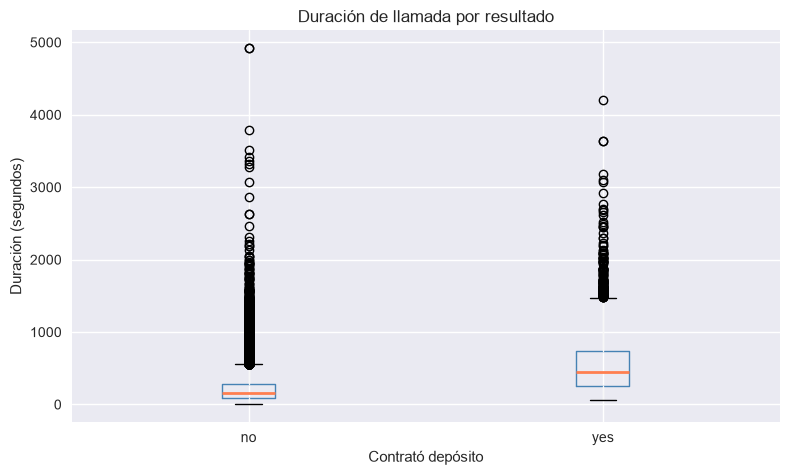

In [211]:
# Boxplot de duración por resultado
fig, ax = plt.subplots(figsize=(8, 5))

df.boxplot(column='duration', by='y', ax=ax, 
           boxprops=dict(color='steelblue'),
           medianprops=dict(color='coral', linewidth=2))

ax.set_title('Duración de llamada por resultado')
ax.set_xlabel('Contrató depósito')
ax.set_ylabel('Duración (segundos)')
plt.suptitle('')  # eliminamos el título automático de boxplot

plt.tight_layout()
plt.savefig('../data/processed/plot_duracion.png', dpi=100)
plt.show()

Ingresos por resultado de campaña:
        mean   median
y                    
no   93297.0  93152.0
yes  92661.0  92380.0


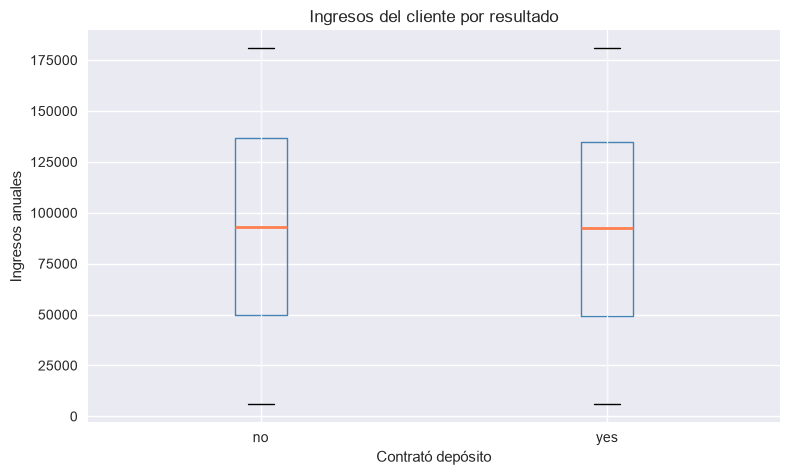

In [212]:
# Analizamos los ingresos de los clientes por resultado
ingresos_conversion = df.groupby('y')['Income'].agg(['mean', 'median']).round(0)
print("Ingresos por resultado de campaña:")
print(ingresos_conversion)

# Visualización
fig, ax = plt.subplots(figsize=(8, 5))
df.boxplot(column='Income', by='y', ax=ax,
           boxprops=dict(color='steelblue'),
           medianprops=dict(color='coral', linewidth=2))

ax.set_title('Ingresos del cliente por resultado')
ax.set_xlabel('Contrató depósito')
ax.set_ylabel('Ingresos anuales')
plt.suptitle('')

plt.tight_layout()
plt.savefig('../data/processed/plot_ingresos.png', dpi=100)
plt.show()

### Ingresos por resultado

Los ingresos anuales son prácticamente iguales entre clientes que contrataron y los que no 
(~93.000 de media en ambos grupos). **Los ingresos no son un factor diferenciador** 
en la decisión de contratar el depósito.

In [213]:
# Tabla pivot: tasa de conversión por trabajo y estado civil
pivot = pd.pivot_table(df, values='y', 
                       index='job', 
                       columns='marital',
                       aggfunc=lambda x: (x == 'yes').sum() / len(x) * 100).round(2)

print("Tasa de conversión (%) por trabajo y estado civil:")
print(pivot)

Tasa de conversión (%) por trabajo y estado civil:
marital        DIVORCED  MARRIED  SINGLE  unknown
job                                              
admin.            10.04    12.54   14.53    14.29
blue-collar        7.59     6.27    8.82    20.00
entrepreneur       7.57     7.84   10.43    33.33
housemaid          9.41     9.65   12.80     0.00
management        11.21    10.89   12.17     0.00
retired           26.11    25.81   13.68    33.33
self-employed     12.14     9.37   14.07     0.00
services           6.08     7.20   10.75     0.00
student           25.00    19.05   32.07     0.00
technician         8.51    10.47   12.17    16.67
unemployed         8.21    14.02   18.94     0.00
unknown           21.43     7.38   19.48    33.33


### Pivot table: conversión por trabajo y estado civil

Los **estudiantes solteros** tienen la tasa de conversión más alta (32%), seguidos de 
**jubilados divorciados** (26%). En general, los clientes **solteros** convierten mejor 
que los casados en casi todos los perfiles de trabajo.

In [214]:
# Guardamos el dataset limpio
df.to_csv(r'C:\Users\mmontllo\Desktop\DATA ANALYTICS\Python for data\proyecto-eda\data\processed\df_limpio.csv', index=False)

print("Dataset guardado en data/processed/df_limpio.csv")
print(f"Shape final: {df.shape}")

Dataset guardado en data/processed/df_limpio.csv
Shape final: (42752, 29)


## 6. Conclusiones

En este análisis he explorado los datos de una campaña de marketing de un banco 
para entender qué factores influyen en que un cliente contrate un depósito a plazo.

### Perfil del cliente que más contrata

Lo primero que llama la atención es que solo el **11.25% de los clientes contactados** 
acabaron contratando el depósito. Es una tasa bastante baja, lo que indica que la 
mayoría de llamadas no convierten.

Mirando por tipo de trabajo, los **estudiantes** (31.4%) y los **jubilados** (25.2%) 
son los que más contratan, muy por encima de la media. Tiene sentido: los jubilados 
suelen buscar productos de ahorro seguros, y los estudiantes quizás tienen más tiempo 
para atender llamadas. Los trabajadores de **cuello azul** son los que menos convierten (6.9%).

Si además segmentamos por franja de edad, los clientes **senior (mayores de 60 años)** 
tienen una tasa de conversión del **39%**, muy superior a cualquier otro grupo de edad. 
Esto refuerza la idea de que los perfiles de más edad son el segmento más receptivo 
a este tipo de producto financiero.

Si además cruzamos trabajo y estado civil con el pivot table, vemos que los 
**estudiantes solteros** alcanzan el **32%** de conversión — el valor más alto de todo el análisis.

### La duración de la llamada importa mucho

Una de las conclusiones más claras del análisis es que los clientes que acabaron 
contratando tuvieron llamadas mucho más largas: **9.2 minutos** de media frente a 
**3.7 minutos** de los que no contrataron. Esto me hace pensar que cuando un cliente 
está interesado, la conversación se alarga de forma natural.

### Los ingresos no marcan la diferencia

Algo que me ha sorprendido es que los ingresos anuales son casi iguales entre los 
dos grupos (~93.000). Es decir, no parece que tener más o menos dinero influya en 
la decisión de contratar el depósito. La edad tampoco muestra diferencias relevantes.

### ¿Qué haría el banco diferente?

A partir de lo que he visto en los datos, si tuviera que recomendar algo para 
mejorar la campaña sería:

- **Priorizar el contacto con jubilados, estudiantes y clientes mayores de 60 años**: 
  son los perfiles con tasas de conversión más altas (39%, 31% y 25% respectivamente). 
  Los clientes de más edad buscan productos de ahorro seguros y estables, mientras que 
  los estudiantes pueden estar empezando a gestionar sus finanzas y son más receptivos 
  a nuevos productos bancarios.

- **Prestar más atención a clientes solteros**: en casi todos los perfiles de trabajo, 
  los solteros convierten mejor que los casados o divorciados. Puede ser porque tienen 
  menos cargas financieras y más flexibilidad para destinar dinero a un depósito a plazo.

- **No cortar las llamadas rápido**: una conversación más larga está claramente asociada 
  a una mayor probabilidad de conversión. Esto sugiere que vale la pena invertir tiempo 
  en explicar bien el producto, ya que los clientes que acaban contratando necesitan 
  más información antes de decidirse.